# Visualizzazioni di V0

Input: /home/alessio-grisorio/TESI/hj_reachability/results/brt/dce.npz
Campo: V0; v_E=6, v_H=6, delta_E=0 rad


/home/alessio-grisorio/TESI/hj_reachability/scripts/compare_terminal_values.py:173: UserWarning: dce: superficie zero tagliata al bordo y_rel.
  warnings.warn(f"{label}: superficie zero tagliata al bordo {NAMES[dim]}.")


<Figure size 1440x600 with 0 Axes>

/home/alessio-grisorio/TESI/hj_reachability/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


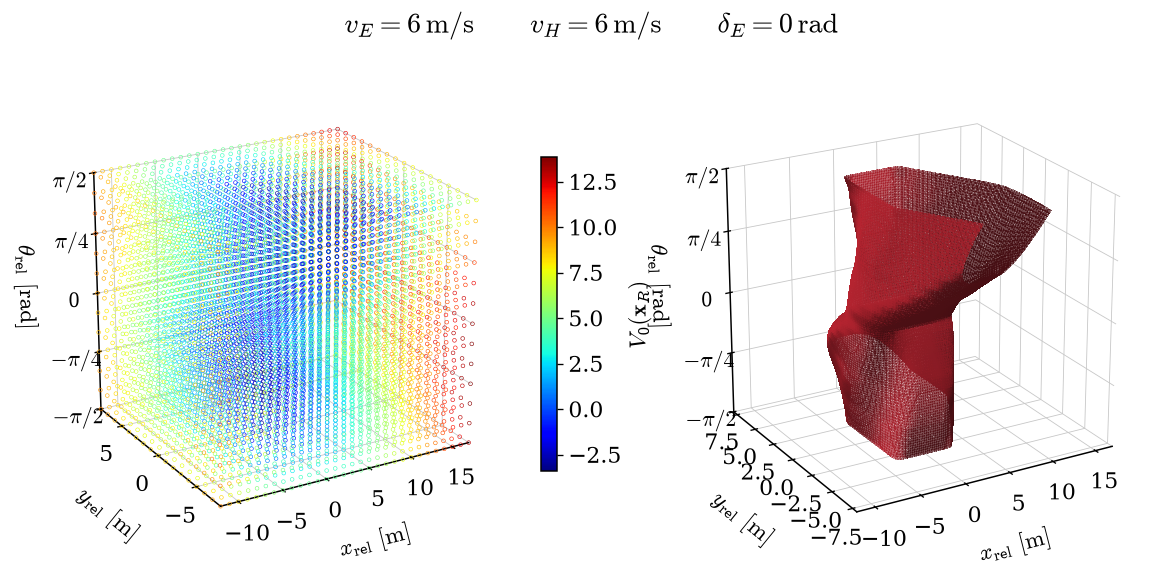

In [3]:
from pathlib import Path
import sys

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm, colors
from plot_utils import set_style, export_figure

set_style()


# Individua la radice del repository.
ROOT = next(
    (
        folder
        for folder in (Path.cwd(), *Path.cwd().parents)
        if (folder / "scripts" / "plot_terminal_value.py").is_file()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        "Apri il notebook all'interno del repository hj_reachability."
    )

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from scripts import plot_terminal_value as terminal
from scripts import compare_terminal_values as comparison


# ---------------- Configurazione ----------------

METRIC = "dce"
DATA_DIRECTORY = ROOT / "results" / "brt"

V_E = 6.0
V_H = 6.0
DELTA_E = 0.0

X_LIMITS = None
Y_LIMITS = None
THETA_LIMITS = (-np.pi / 2, np.pi / 2)

FIGURE_SIZE = (12.0, 5.0)
ELEVATION = 22
AZIMUTH = -120

COLORMAP = "jet"
COLOR_LIMITS = None
SCATTER_STRIDE = (1, 1, 2)
SCATTER_SIZE = 5.0

SURFACE_COLOR = plt.get_cmap("RdBu_r")(0.88)
SURFACE_ALPHA = 0.5
SURFACE_REFINEMENT = 4
SMOOTHING_SIGMA = 0.8

# ------------------------------------------------


terminal.KEY = "V0"
terminal.DATA_DIRECTORY = DATA_DIRECTORY
terminal.INPUT_FILE = None

terminal.V_E = V_E
terminal.V_H = V_H
terminal.DELTA_E = DELTA_E

terminal.X_LIMITS = X_LIMITS
terminal.Y_LIMITS = Y_LIMITS
terminal.THETA_LIMITS = THETA_LIMITS
terminal.ELEVATION = ELEVATION
terminal.AZIMUTH = AZIMUTH

comparison.V_E_3D = V_E
comparison.V_H = V_H
comparison.DELTA_E = DELTA_E
comparison.SURFACE_ALPHA = SURFACE_ALPHA
comparison.SURFACE_REFINEMENT = SURFACE_REFINEMENT
comparison.SMOOTHING_SIGMA = SMOOTHING_SIGMA


# Carica V0 e interpola nelle coordinate fissate.
axes, values, field_label = terminal.load_slice(METRIC)
extended_axes, extended_values, limits = terminal.prepare_domain(
    axes, values
)

interpolator = terminal.RegularGridInterpolator(
    extended_axes,
    extended_values,
    bounds_error=True,
)

scatter_axes = [
    axis[
        (axis >= lower - 1e-7)
        & (axis <= upper + 1e-7)
    ][::stride]
    for axis, (lower, upper), stride in zip(
        axes, limits, SCATTER_STRIDE
    )
]

if any(len(axis) == 0 for axis in scatter_axes):
    raise ValueError("Nessun nodo scatter nei limiti selezionati.")

points = np.stack(
    np.meshgrid(*scatter_axes, indexing="ij"),
    axis=-1,
).reshape(-1, 3)

point_values = interpolator(points)

vmin, vmax = (
    COLOR_LIMITS
    if COLOR_LIMITS is not None
    else (float(values.min()), float(values.max()))
)

if not vmin < vmax:
    raise ValueError("Seleziona limiti colore con minimo < massimo.")

norm = colors.Normalize(vmin=vmin, vmax=vmax)
cmap = plt.get_cmap(COLORMAP)


# Figura nello stile del grafico 3D originale.
fig_v0 = plt.figure(figsize=FIGURE_SIZE, layout="none")

fig_v0 = plt.figure(
    figsize=FIGURE_SIZE,
    layout="constrained",
)

ax_scatter = fig_v0.add_subplot(121, projection="3d")
ax_surface = fig_v0.add_subplot(122, projection="3d")

for ax in (ax_scatter, ax_surface):
    terminal.configure_axis(ax, limits)
    ax.tick_params(labelsize=plt.rcParams["xtick.labelsize"])

ax_scatter.scatter(
    *points.T,
    s=SCATTER_SIZE,
    facecolors="none",
    edgecolors=cmap(norm(point_values)),
    linewidths=0.35,
    depthshade=False,
    rasterized=True,
)

colorbar = fig_v0.colorbar(
    cm.ScalarMappable(norm=norm, cmap=cmap),
    ax=ax_scatter,
    shrink=0.68,
    pad=0.08,
    fraction=0.035,
)

colorbar.set_label(rf"${field_label}$")
colorbar.ax.tick_params(labelsize=plt.rcParams["ytick.labelsize"])

# La routine dei confronti riceve una fetta già fissata:
# gli ultimi tre assi sono quindi singleton.
surface_axes = [
    *axes,
    np.array([V_H]),
    np.array([DELTA_E]),
    np.array([V_E]),
]

comparison.plot_surface(
    ax_surface,
    surface_axes,
    values[..., None, None, None],
    SURFACE_COLOR,
    METRIC,
    limits,
)
fig_v0.suptitle(
    rf"$v_E={V_E:g}\,\mathrm{{m/s}}"
    rf"\qquad v_H={V_H:g}\,\mathrm{{m/s}}"
    rf"\qquad \delta_E={DELTA_E:g}\,\mathrm{{rad}}$",
    y=1.0,
)
plt.show()



In [4]:
export_figure(
    fig_v0,
    nome="dce_v0",
    cartella=METRIC,
    formati=("pdf", "eps"),
    sovrascrivi=True,
)

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Salvato: /home/alessio-grisorio/TESI/hj_reachability/grafici/output/dce/dce_v0.pdf


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as uni

Salvato: /home/alessio-grisorio/TESI/hj_reachability/grafici/output/dce/dce_v0.eps


[PosixPath('/home/alessio-grisorio/TESI/hj_reachability/grafici/output/dce/dce_v0.pdf'),
 PosixPath('/home/alessio-grisorio/TESI/hj_reachability/grafici/output/dce/dce_v0.eps')]

## mosaico 3x3

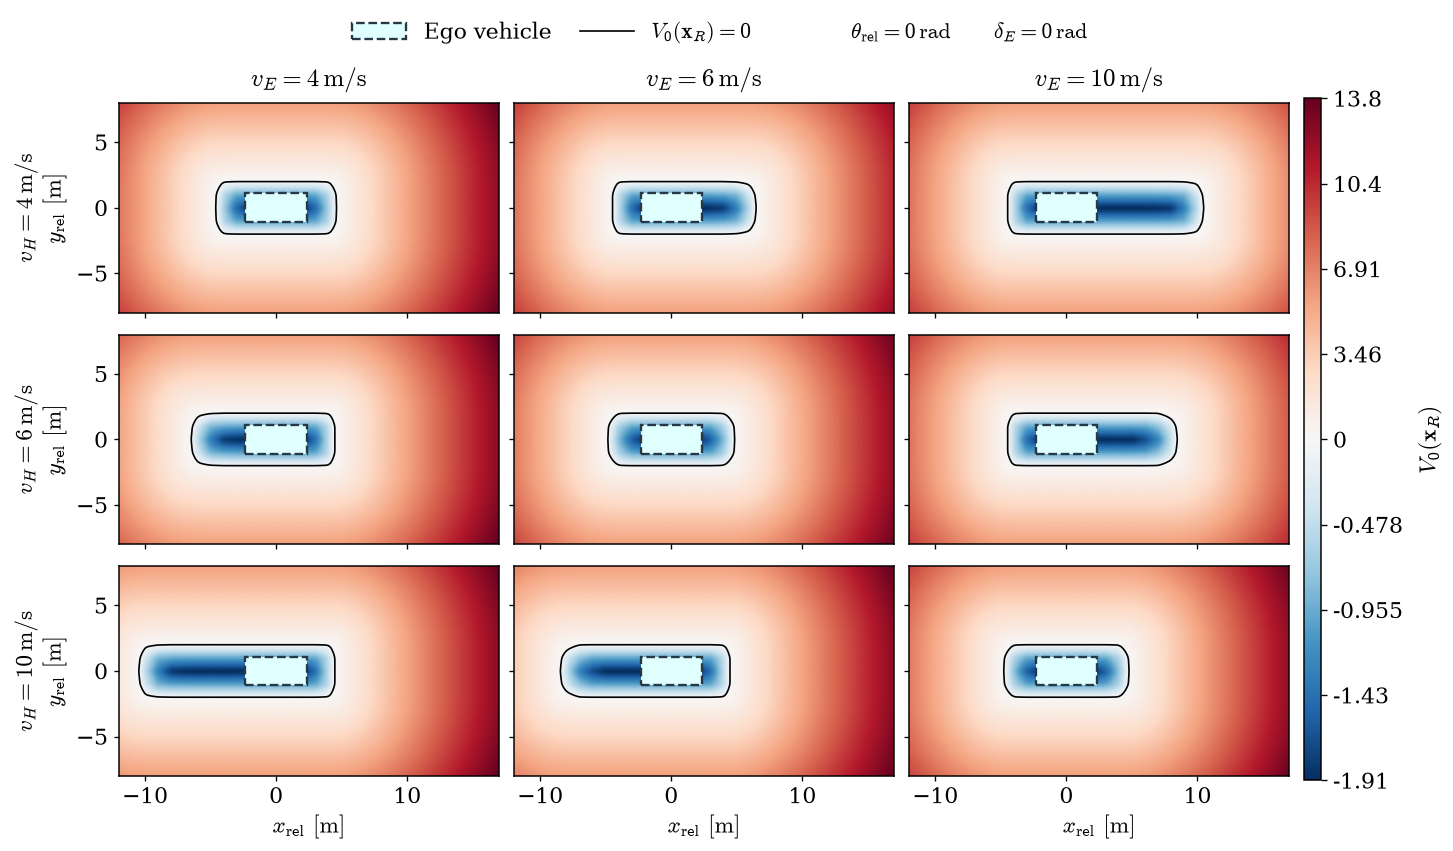

In [5]:
from matplotlib.colors import Normalize, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from scipy.interpolate import RegularGridInterpolator
from scipy.ndimage import gaussian_filter
from scripts.plot_terminal_slices import bracket

# Colonne: velocità ego; righe: velocità human.
V_E_VALUES = (4.0, 6.0, 10.0)
V_H_VALUES = (4.0, 6.0, 10.0)
THETA_MOSAIC = 0.0
DELTA_MOSAIC = 0.0
MOSAIC_SIZE = (12.0, 7.0)
MOSAIC_X_LIMITS = None
MOSAIC_Y_LIMITS = None
MOSAIC_REFINEMENT = 6
MOSAIC_SMOOTHING = 0.8
MOSAIC_COLORMAP = "RdBu_r"


def make_speed_mosaic(field_key):
    """Crea il mosaico senza esportarlo."""
    if len(V_E_VALUES) != 3 or len(V_H_VALUES) != 3:
        raise ValueError("Specificare tre velocità ego e tre velocità human.")
    if int(MOSAIC_REFINEMENT) != MOSAIC_REFINEMENT or MOSAIC_REFINEMENT < 1:
        raise ValueError("Raffinamento intero positivo richiesto.")
    if MOSAIC_SMOOTHING < 0:
        raise ValueError("Lo smoothing deve essere >= 0.")
    names = ("x_rel", "y_rel", "theta_rel", "v_H", "delta_E", "v_E")
    rendered = {}
    with np.load(DATA_DIRECTORY / f"{METRIC}.npz", allow_pickle=False) as data:
        grid_axes = [np.asarray(data[n], dtype=float) for n in names]
        if "state_names" in data and tuple(data["state_names"].tolist()) != names:
            raise ValueError("Ordine degli stati incompatibile.")
        for name, axis in zip(names, grid_axes):
            if (axis.ndim != 1 or len(axis) < 1 or not np.isfinite(axis).all()
                    or not np.all(np.diff(axis) > 0)):
                raise ValueError(f"Asse non valido: {name}")
        time = float(data["target_time"]) if field_key == "BRT" else None
        x, y = grid_axes[:2]
        limits_xy = [
            MOSAIC_X_LIMITS if MOSAIC_X_LIMITS is not None else (x[0], x[-1]),
            MOSAIC_Y_LIMITS if MOSAIC_Y_LIMITS is not None else (y[0], y[-1]),
        ]
        for axis, (lo, hi) in zip((x, y), limits_xy):
            if lo >= hi or lo < axis[0] or hi > axis[-1]:
                raise ValueError("Limiti spaziali fuori dal dominio.")
        fine_axes = [
            np.linspace(a[0], a[-1], (len(a)-1)*int(MOSAIC_REFINEMENT)+1)
            for a in (x, y)
        ]
        fine_points = np.stack(np.meshgrid(*fine_axes, indexing="ij"), axis=-1)
        crop_axes = [
            np.unique(np.r_[lo, a[(a > lo) & (a < hi)], hi])
            for a, (lo, hi) in zip(fine_axes, limits_xy)
        ]
        crop_points = np.stack(np.meshgrid(*crop_axes, indexing="ij"), axis=-1)
        for key in (("BRT", "V0") if field_key == "BRT" else ("V0",)):
            field = data[key]
            if field.shape != tuple(len(a) for a in grid_axes):
                raise ValueError(f"Forma incompatibile: {key}")
            rendered[key] = []
            for vh in V_H_VALUES:
                for ve in V_E_VALUES:
                    section = field
                    for dim, value in (
                        (5, ve), (4, DELTA_MOSAIC), (3, vh), (2, THETA_MOSAIC),
                    ):
                        lo, hi, w = bracket(
                            grid_axes[dim], value, names[dim], periodic=(dim == 2)
                        )
                        section = ((1-w)*np.take(section, lo, axis=dim)
                                   + w*np.take(section, hi, axis=dim))
                    fine = RegularGridInterpolator((x, y), section)(fine_points)
                    if MOSAIC_SMOOTHING:
                        fine = gaussian_filter(fine, sigma=MOSAIC_SMOOTHING, mode="nearest")
                    plotted = RegularGridInterpolator(tuple(fine_axes), fine)(crop_points)
                    if not np.isfinite(plotted).all():
                        raise ValueError("Fetta con NaN o infiniti.")
                    rendered[key].append(plotted)
            del field, section

    sections = rendered[field_key]
    lower = min(float(s.min()) for s in sections)
    upper = max(float(s.max()) for s in sections)
    if lower >= upper:
        raise ValueError("Colorbar degenere.")
    norm = (TwoSlopeNorm(vmin=lower, vcenter=0.0, vmax=upper)
            if lower < 0 < upper else Normalize(vmin=lower, vmax=upper))
    label = (rf"V({time:g},\mathbf{{x}}_R)"
             if field_key == "BRT" else r"V_0(\mathbf{x}_R)")
    set_style()
    fig = plt.figure(figsize=MOSAIC_SIZE, layout="constrained")
    grid = fig.add_gridspec(
        4, 4, width_ratios=(1, 1, 1, 0.045), height_ratios=(0.20, 1, 1, 1),
    )
    header = fig.add_subplot(grid[0, :])
    header.set_axis_off()
    handles = [
        Patch(facecolor="lightcyan", edgecolor="#263746",
              linewidth=1.4, linestyle="--", label="Ego vehicle"),
        Line2D([], [], color="black", linewidth=1.0, label="$"+label+"=0$"),
    ]
    if field_key == "BRT":
        handles.append(Line2D(
            [], [], color="#287a32", linewidth=1.4, linestyle="--",
            label=r"$V_0(\mathbf{x}_R)=0$",
        ))
    handles.append(Line2D(
        [], [], linestyle="none",
        label=rf"$\theta_{{\mathrm{{rel}}}}={THETA_MOSAIC:g}\,\mathrm{{rad}}"
              rf"\qquad\delta_E={DELTA_MOSAIC:g}\,\mathrm{{rad}}$",
    ))
    header.legend(
        handles=handles, loc="center", ncol=len(handles),
        frameon=False, handlelength=2.5, columnspacing=1.3,
    )
    panels = []
    for index, section in enumerate(sections):
        row, column = divmod(index, 3)
        ax = fig.add_subplot(
            grid[row+1, column],
            sharex=panels[0] if panels else None,
            sharey=panels[0] if panels else None,
        )
        panels.append(ax)
        image = ax.pcolormesh(
            *crop_axes, section.T, shading="gouraud",
            cmap=MOSAIC_COLORMAP, norm=norm, rasterized=True,
        )
        if section.min() < 0 < section.max():
            ax.contour(*crop_axes, section.T, levels=[0], colors="black", linewidths=1.0)
        if field_key == "BRT":
            initial = rendered["V0"][index]
            if initial.min() < 0 < initial.max():
                ax.contour(
                    *crop_axes, initial.T, levels=[0], colors="#287a32",
                    linewidths=1.4, linestyles="--", zorder=4,
                )
        ax.add_patch(Rectangle(
            (-4.68/2, -2.20/2), 4.68, 2.20,
            facecolor="lightcyan", edgecolor="#263746",
            linewidth=1.4, linestyle="--", zorder=5,
        ))
        ax.set_xlim(limits_xy[0])
        ax.set_ylim(limits_xy[1])
        ax.set_aspect("equal", adjustable="box")
        ax.tick_params(direction="out", length=3,
                       labelbottom=(row == 2), labelleft=(column == 0))
        if row == 2:
            ax.set_xlabel(r"$x_{\mathrm{rel}}\ [\mathrm{m}]$")
        if column == 0:
            ax.set_ylabel(
                rf"$v_H={V_H_VALUES[row]:g}\,\mathrm{{m/s}}$"
                "\n" r"$y_{\mathrm{rel}}\ [\mathrm{m}]$"
            )
        if row == 0:
            ax.set_title(rf"$v_E={V_E_VALUES[column]:g}\,\mathrm{{m/s}}$", pad=10)
    cax = fig.add_subplot(grid[1:, 3])
    bar = fig.colorbar(image, cax=cax)
    ticks = (np.r_[np.linspace(lower, 0, 5), np.linspace(0, upper, 5)[1:]]
             if lower < 0 < upper else np.linspace(lower, upper, 7))
    bar.set_ticks(ticks)
    bar.set_ticklabels([f"{value:.3g}" for value in ticks])
    bar.set_label("$"+label+"$", labelpad=9)
    return fig


fig_v0_slices = make_speed_mosaic("V0")
plt.show()



In [6]:

SALVA = True

if SALVA:
    export_figure(
        fig_v0_slices,
        nome="dce_v0_slices",
        cartella=METRIC,
        formati=("pdf", "eps"),
        sovrascrivi=True,
    )


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Salvato: /home/alessio-grisorio/TESI/hj_reachability/grafici/output/dce/dce_v0_slices.pdf


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Salvato: /home/alessio-grisorio/TESI/hj_reachability/grafici/output/dce/dce_v0_slices.eps


## BRT scatter e isosup

Input: /home/alessio-grisorio/TESI/hj_reachability/results/brt/dce.npz
Campo: BRT; v_E=6, v_H=6, delta_E=0 rad


/home/alessio-grisorio/TESI/hj_reachability/scripts/compare_terminal_values.py:173: UserWarning: dce: superficie zero tagliata al bordo y_rel.
  warnings.warn(f"{label}: superficie zero tagliata al bordo {NAMES[dim]}.")
/home/alessio-grisorio/TESI/hj_reachability/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


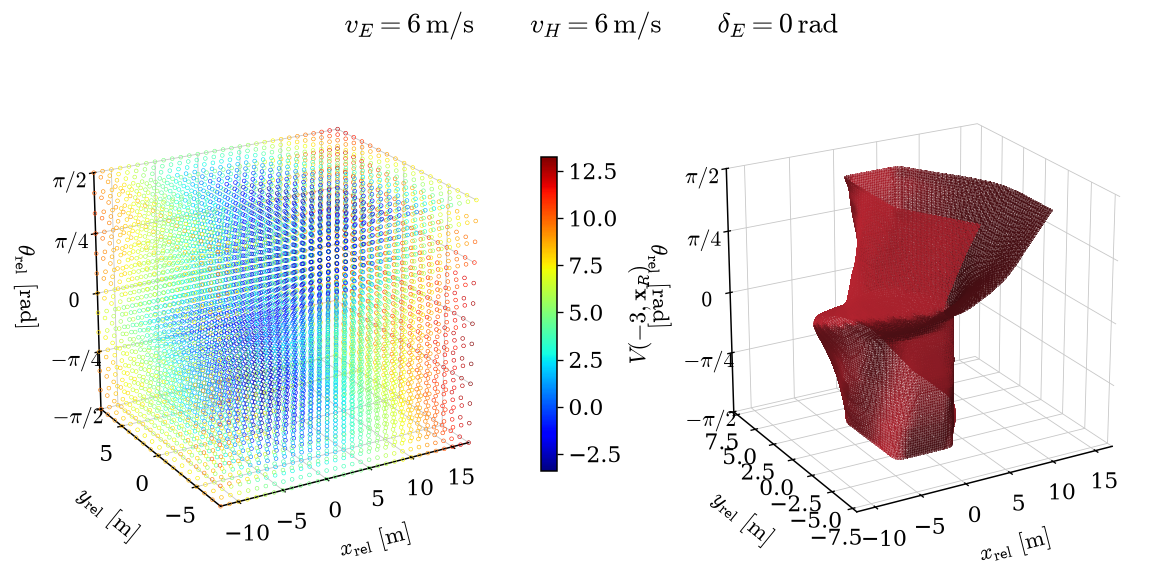

In [9]:
from pathlib import Path
import sys

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm, colors
from plot_utils import set_style, export_figure

set_style()


# Individua la radice del repository.
ROOT = next(
    (
        folder
        for folder in (Path.cwd(), *Path.cwd().parents)
        if (folder / "scripts" / "plot_terminal_value.py").is_file()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        "Apri il notebook all'interno del repository hj_reachability."
    )

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from scripts import plot_terminal_value as terminal
from scripts import compare_terminal_values as comparison


# ---------------- Configurazione ----------------

METRIC = "dce"
DATA_DIRECTORY = ROOT / "results" / "brt"

V_E = 6.0
V_H = 6.0
DELTA_E = 0.0

X_LIMITS = None
Y_LIMITS = None
THETA_LIMITS = (-np.pi / 2, np.pi / 2)

FIGURE_SIZE = (12.0, 5.0)
ELEVATION = 22
AZIMUTH = -120

COLORMAP = "jet"
COLOR_LIMITS = None
SCATTER_STRIDE = (1, 1, 2)
SCATTER_SIZE = 5.0

SURFACE_COLOR = plt.get_cmap("RdBu_r")(0.88)
SURFACE_ALPHA = 0.5
SURFACE_REFINEMENT = 4
SMOOTHING_SIGMA = 0.8

# ------------------------------------------------


terminal.KEY = "BRT"
terminal.DATA_DIRECTORY = DATA_DIRECTORY
terminal.INPUT_FILE = None

terminal.V_E = V_E
terminal.V_H = V_H
terminal.DELTA_E = DELTA_E

terminal.X_LIMITS = X_LIMITS
terminal.Y_LIMITS = Y_LIMITS
terminal.THETA_LIMITS = THETA_LIMITS
terminal.ELEVATION = ELEVATION
terminal.AZIMUTH = AZIMUTH

comparison.V_E_3D = V_E
comparison.V_H = V_H
comparison.DELTA_E = DELTA_E
comparison.SURFACE_ALPHA = SURFACE_ALPHA
comparison.SURFACE_REFINEMENT = SURFACE_REFINEMENT
comparison.SMOOTHING_SIGMA = SMOOTHING_SIGMA


# Carica il BRT e interpola nelle coordinate fissate.
axes, values, field_label = terminal.load_slice(METRIC)
extended_axes, extended_values, limits = terminal.prepare_domain(
    axes, values
)

interpolator = terminal.RegularGridInterpolator(
    extended_axes,
    extended_values,
    bounds_error=True,
)

scatter_axes = [
    axis[
        (axis >= lower - 1e-7)
        & (axis <= upper + 1e-7)
    ][::stride]
    for axis, (lower, upper), stride in zip(
        axes, limits, SCATTER_STRIDE
    )
]

if any(len(axis) == 0 for axis in scatter_axes):
    raise ValueError("Nessun nodo scatter nei limiti selezionati.")

points = np.stack(
    np.meshgrid(*scatter_axes, indexing="ij"),
    axis=-1,
).reshape(-1, 3)

point_values = interpolator(points)

vmin, vmax = (
    COLOR_LIMITS
    if COLOR_LIMITS is not None
    else (float(values.min()), float(values.max()))
)

if not vmin < vmax:
    raise ValueError("Seleziona limiti colore con minimo < massimo.")

norm = colors.Normalize(vmin=vmin, vmax=vmax)
cmap = plt.get_cmap(COLORMAP)


# Figura nello stile del grafico 3D originale.
fig_brt = plt.figure(figsize=FIGURE_SIZE, layout="constrained")

ax_scatter = fig_brt.add_subplot(121, projection="3d")
ax_surface = fig_brt.add_subplot(122, projection="3d")

for ax in (ax_scatter, ax_surface):
    terminal.configure_axis(ax, limits)
    ax.tick_params(labelsize=plt.rcParams["xtick.labelsize"])

ax_scatter.scatter(
    *points.T,
    s=SCATTER_SIZE,
    facecolors="none",
    edgecolors=cmap(norm(point_values)),
    linewidths=0.35,
    depthshade=False,
    rasterized=True,
)

colorbar = fig_brt.colorbar(
    cm.ScalarMappable(norm=norm, cmap=cmap),
    ax=ax_scatter,
    shrink=0.68,
    pad=0.08,
    fraction=0.035,
)

colorbar.set_label(rf"${field_label}$")
colorbar.ax.tick_params(labelsize=plt.rcParams["ytick.labelsize"])

# La routine dei confronti riceve una fetta già fissata:
# gli ultimi tre assi sono quindi singleton.
surface_axes = [
    *axes,
    np.array([V_H]),
    np.array([DELTA_E]),
    np.array([V_E]),
]

comparison.plot_surface(
    ax_surface,
    surface_axes,
    values[..., None, None, None],
    SURFACE_COLOR,
    METRIC,
    limits,
)
fig_brt.suptitle(
    rf"$v_E={V_E:g}\,\mathrm{{m/s}}"
    rf"\qquad v_H={V_H:g}\,\mathrm{{m/s}}"
    rf"\qquad \delta_E={DELTA_E:g}\,\mathrm{{rad}}$",
    y=1.0,
)
plt.show()



In [10]:
# Imposta True ed esegui questa cella per esportare.
SALVA = True

if SALVA:
    export_figure(
        fig_brt,
        nome="dce_brt",
        cartella=METRIC,
        formati=("pdf", "eps"),
        sovrascrivi=True,
    )


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Salvato: /home/alessio-grisorio/TESI/hj_reachability/grafici/output/dce/dce_brt.pdf


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as uni

Salvato: /home/alessio-grisorio/TESI/hj_reachability/grafici/output/dce/dce_brt.eps


## brt mosaico 3x3

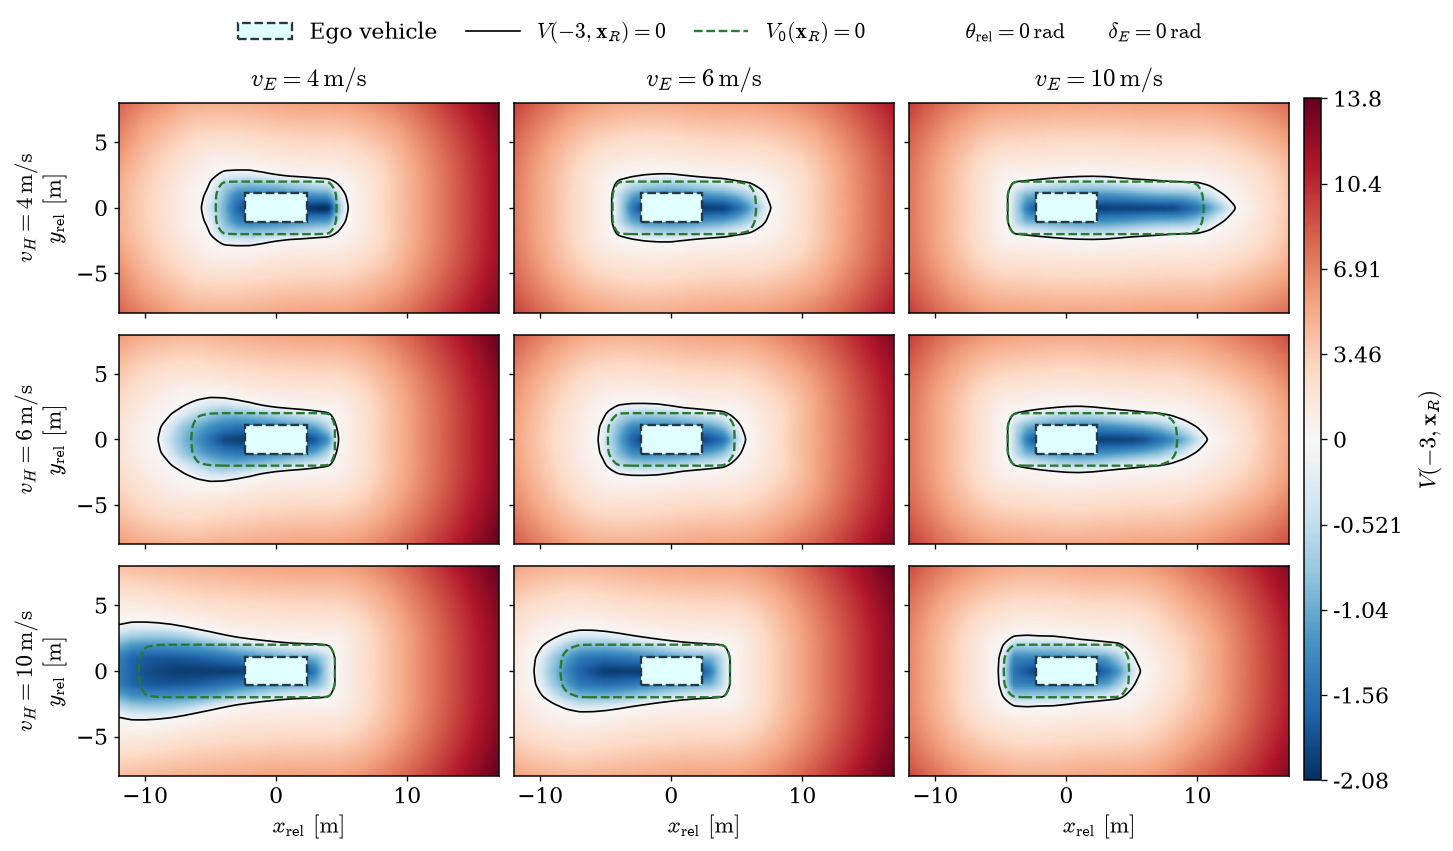

In [11]:
fig_brt_slices = make_speed_mosaic("BRT")
plt.show()


In [12]:
# Imposta True ed esegui questa cella per esportare.
SALVA = True

if SALVA:
    export_figure(
        fig_brt_slices,
        nome="dce_brt_slices",
        cartella=METRIC,
        formati=("pdf", "eps"),
        sovrascrivi=True,
    )


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Salvato: /home/alessio-grisorio/TESI/hj_reachability/grafici/output/dce/dce_brt_slices.pdf


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very l

Salvato: /home/alessio-grisorio/TESI/hj_reachability/grafici/output/dce/dce_brt_slices.eps
